# SPACEc: Tissue Extractor

This script takes a 3D tiff or qptiff fluorescent image containing multiple tissues, crops each tissue out of the larger image, and saves a tiff subimage for each tissue. It expects images of dimension (cycles, Ypixels, Xpixels). The script is based on image segmentation principles and code presented on the scikit-image site at this link (https://scikit-image.org/docs/dev/user_guide/tutorial_segmentation.html). 

The steps of the script are:

1. The image is downsized by downscale_factor in each dimension. 
2. A Gaussian filter with std. dev. equal to sigma is applied to the image to remove outliers.
3. Watershed segmentation is applied to segment the image into individual tissues.
4. (Optional) User can manually clean up tissue piece region assignments
5. A bounding box is generated around each region.
6. Each bounding box is used to crop the original full tiff stack.
7. The resulting cropped tiff stack of each region is saved as its own tiff.

In [1]:
# import spacec first
import spacec as sp

# import standard packages
import os
import warnings
import numpy as np
import scanpy as sc
import matplotlib

warnings.filterwarnings('ignore')

In [2]:
# Apply SPACEc publication style to all plots in this notebook
sp.pl.set_style(sp.pl.SPACEcStyle.publication())

In [ ]:
# Specify the path to the data
data_path = "path/to/example_data/raw/"
output_dir = "path/to/output/"
os.makedirs(output_dir, exist_ok=True)

In [4]:
# specify the image file for extraction
file = 'tonsil_tma.tif' # the file name of the image, can be qptiff or tiff
file_path = data_path + file # the path to the image

## Downscale CODEX images

[downscale_tissue] Starting tissue downscaling workflow.
[downscale_tissue] This function prepares a low-resolution nuclear image for tissue segmentation.
[downscale_tissue] 
[downscale_tissue] Watershed cutoff interpretation:
[downscale_tissue]   lower_cutoff marks confident background pixels.
[downscale_tissue]   upper_cutoff marks confident tissue/foreground pixels.
[downscale_tissue]   pixels between lower_cutoff and upper_cutoff are assigned by watershed.
[downscale_tissue] 
[downscale_tissue] Because upper_cutoff is a foreground marker threshold, it should not usually
[downscale_tissue] be set to an extreme high percentile. Very high values can select only bright
[downscale_tissue] tissue cores and miss dimmer tissue edges.
[downscale_tissue] 
[downscale_tissue] Requested DNA/nuclear slice index: 0
[downscale_tissue] Downscale factor: 64
[downscale_tissue] Gaussian smoothing sigma: 5.0
[downscale_tissue] Lower cutoff margin: 0.05
[downscale_tissue] Upper cutoff margin: 0.1
[downs

[downscale_tissue] Step 2/7: Extracting the selected nuclear/DNA channel.
[downscale_tissue] Loaded nuclear image with shape Y x X = 3139 x 5865
[downscale_tissue] Input image dtype: uint8
[downscale_tissue] Step 3/7: Downscaling image with anti-aliasing.
[downscale_tissue] Downscaling from 3139 x 5865 to 49 x 91 pixels.


[downscale_tissue] Step 4/7: Applying Gaussian smoothing to reduce small local intensity variation.
[downscale_tissue] Step 5/7: Computing intensity statistics and watershed cutoff recommendations.
[downscale_tissue] Trying Otsu thresholding for the lower/background cutoff.
[downscale_tissue] Otsu threshold succeeded: 0.2497
[downscale_tissue] 
[downscale_tissue] Lower cutoff recommendation:
[downscale_tissue]   Recommended lower_cutoff = 0.1997
[downscale_tissue]   Meaning in label_tissue:
[downscale_tissue]     markers[resized_im <= lower_cutoff] = 1
[downscale_tissue]   These pixels are treated as confident background markers.
[downscale_tissue] 
[downscale_tissue] Upper cutoff recommendation:
[downscale_tissue]   Recommended upper_cutoff = 0.2997
[downscale_tissue]   Meaning in label_tissue:
[downscale_tissue]     markers[resized_im >= upper_cutoff] = 2
[downscale_tissue]   These pixels are treated as confident tissue/foreground markers.
[downscale_tissue] 
[downscale_tissue] Impor

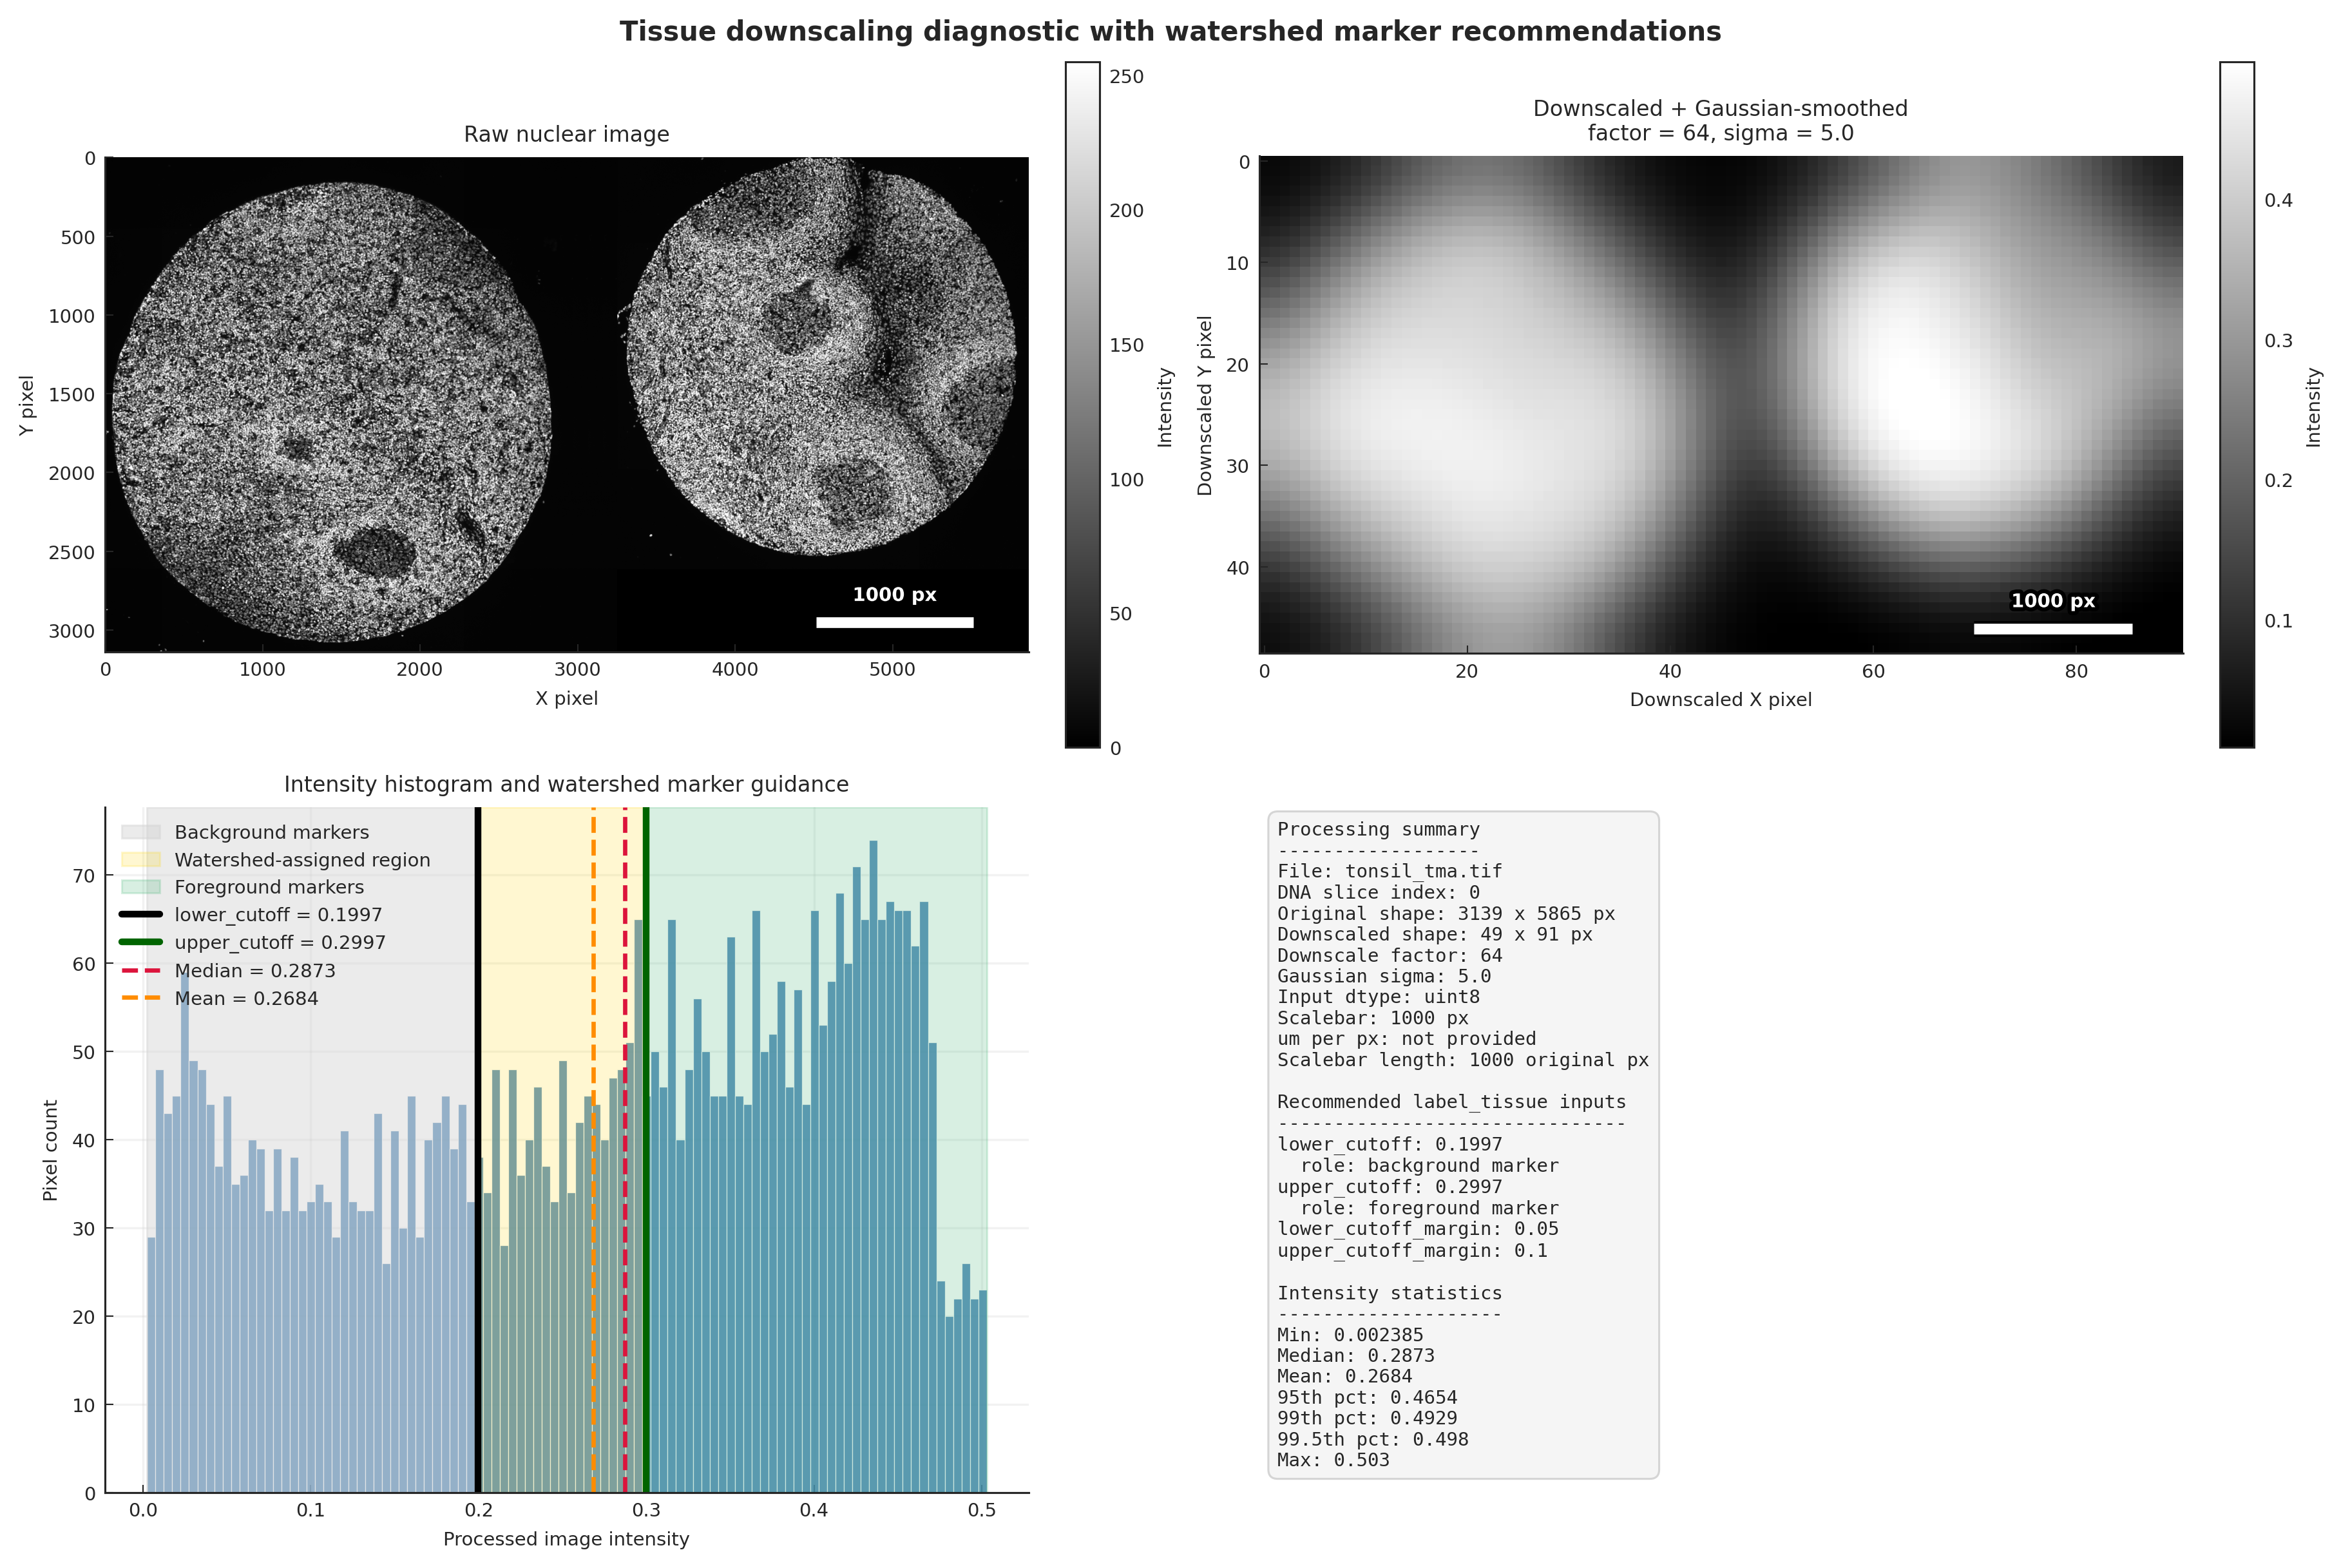

[downscale_tissue] Finished tissue downscaling workflow.
[downscale_tissue] Returning scaled down image.


In [5]:
# downscale your image for easy segmentation computation
resized_im = sp.hf.downscale_tissue(file_path = file_path, # where qptiff or tiff is stored
                                    downscale_factor = 64, # the downscale factor for the image
                                    padding = 50, # the padding to add to the image
                                    output_dir = output_dir # where to store the downscale image
                                    )

## Segment individual tissue pieces

Identified 2 tissue pieces


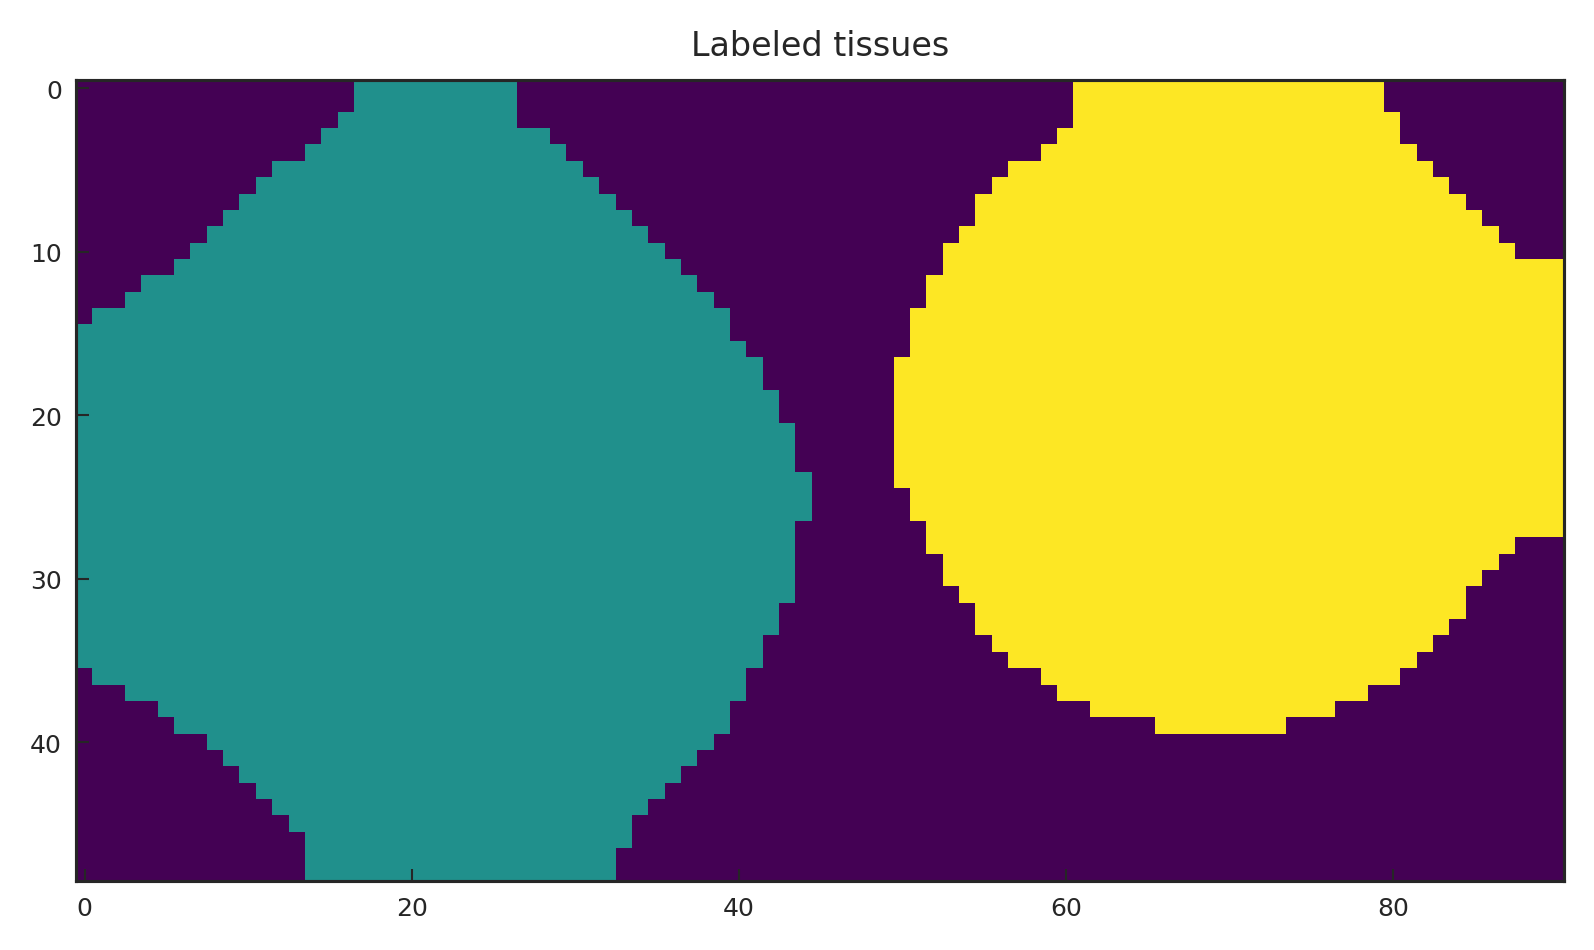

Saving the labels from the segmentation!


In [6]:
tissueframe = sp.tl.label_tissue(resized_im, # the downsampled image
                                 lower_cutoff = 0.2, #the lower cutoff of the image intensity for the tissue
                                 upper_cutoff = 0.21 #the upper cutoff of the image intensity for the tissue
                                 )

In [7]:
tissueframe.head()

,tissue,y,x,region1
0,1,0,17,1
1,1,0,18,1
2,1,0,19,1
3,1,0,20,1
4,1,0,21,1


## Rename tissue number (optional)

[tissue_lables] Starting tissue label plotting.
[tissue_lables] This function visualizes the segmentation output from label_tissue().
[tissue_lables] Using region column: region1
[tissue_lables] Number of segmented pixels in tissueframe: 2891
[tissue_lables] Column 'region1' is still identical to 'tissue'. Showing a single panel. Assign tissue pieces to regions (e.g. tissueframe['region1'] = tissueframe['tissue'].map({1: 1, 2: 1, 3: 2})) to see the region panel.
[tissue_lables] No resized_im background was provided. The figure will show reconstructed label masks only.
[tissue_lables] Plot canvas size: 49 x 91 pixels.
[tissue_lables] Reconstructing a label image from tissueframe coordinates.
[tissue_lables] Found 2 tissue piece(s).
[tissue_lables] Reconstructing a region-label image.
[tissue_lables] Found 2 unique region label(s) in column 'region1'.
[tissue_lables] Computing tissue centroids for label annotation.
[tissue_lables] No cutoff dictionary was provided. If available, pass cut

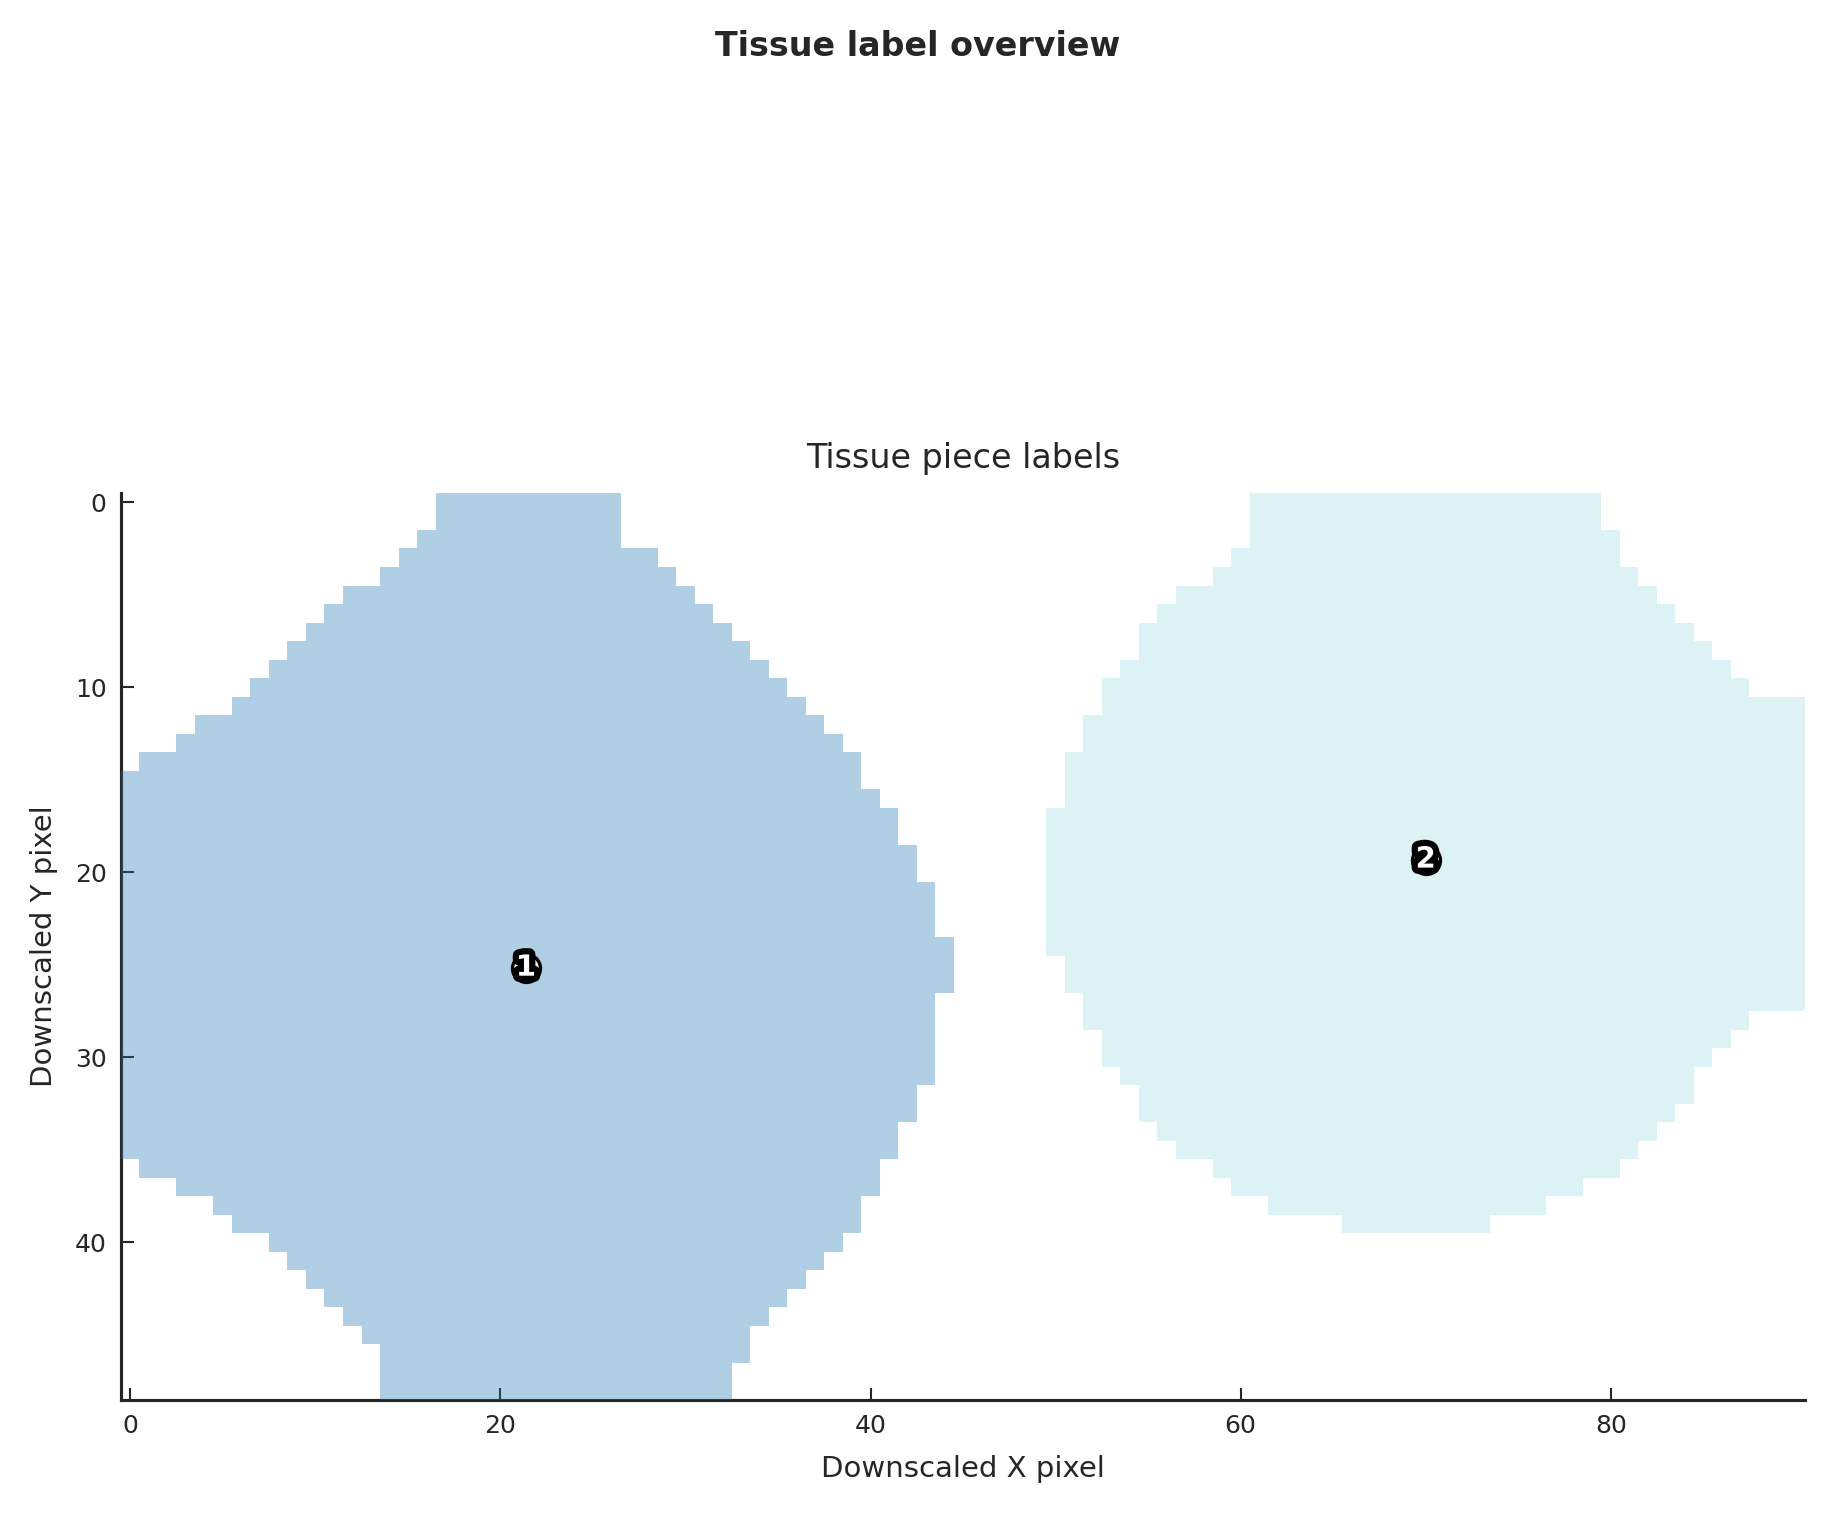

[tissue_lables] Finished tissue label plotting.


In [8]:
# Manually assign the tissue pieces to the regions
sp.pl.tissue_lables(tissueframe=tissueframe, #the data frame with pixel assignment to each tissue piece or region
                    region = 'region1')

## Extract individual labeled tissue

Reading in the qptiff file, might take awhile!


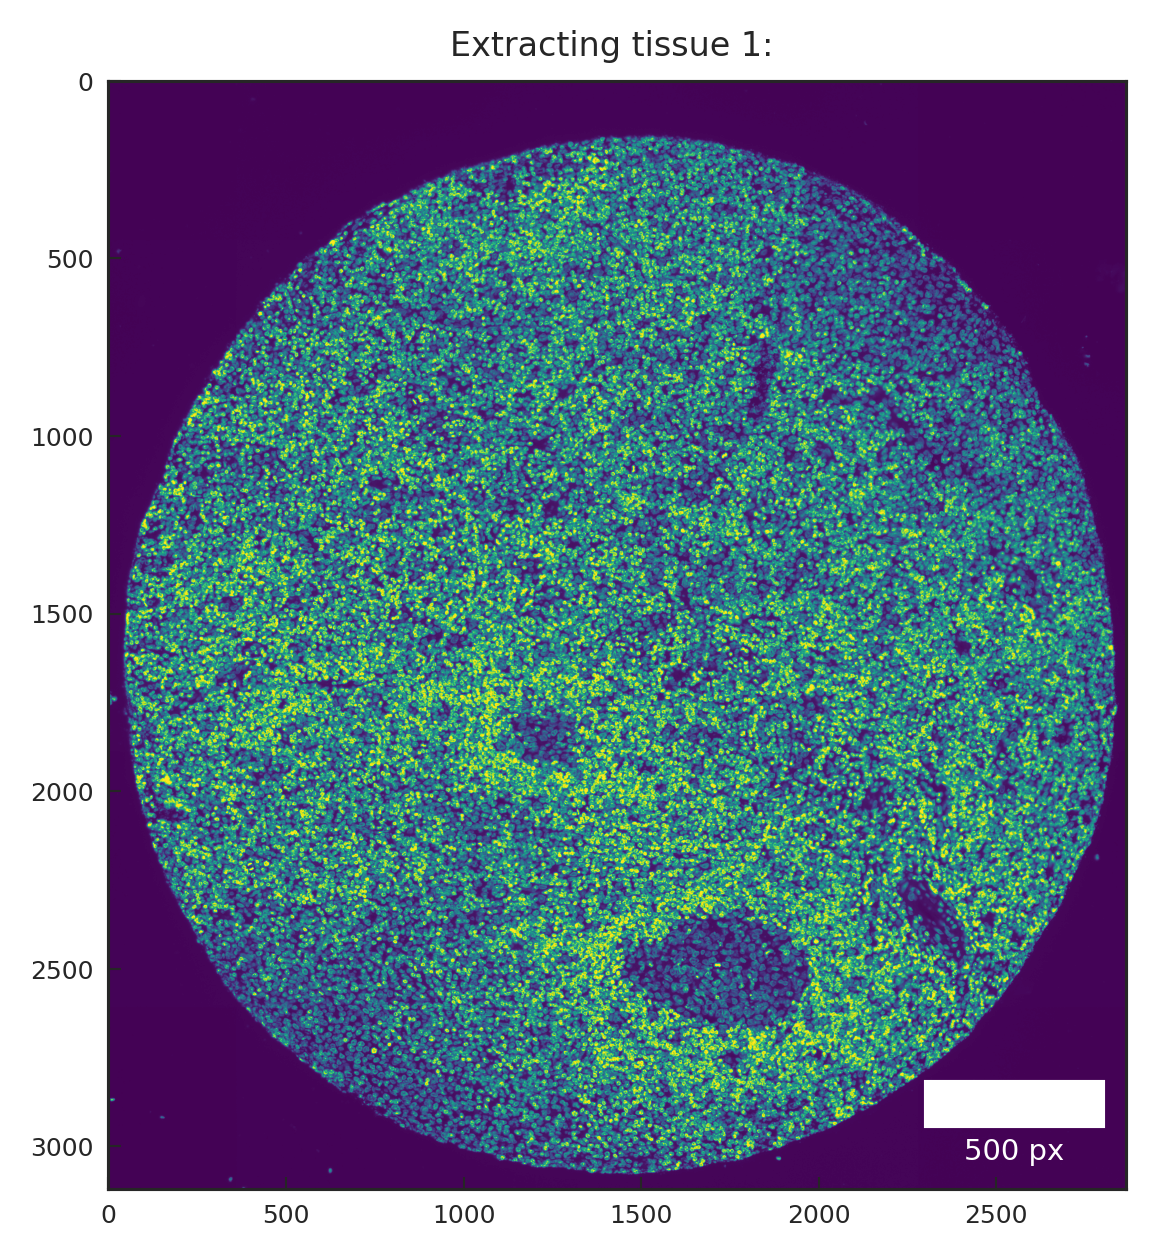

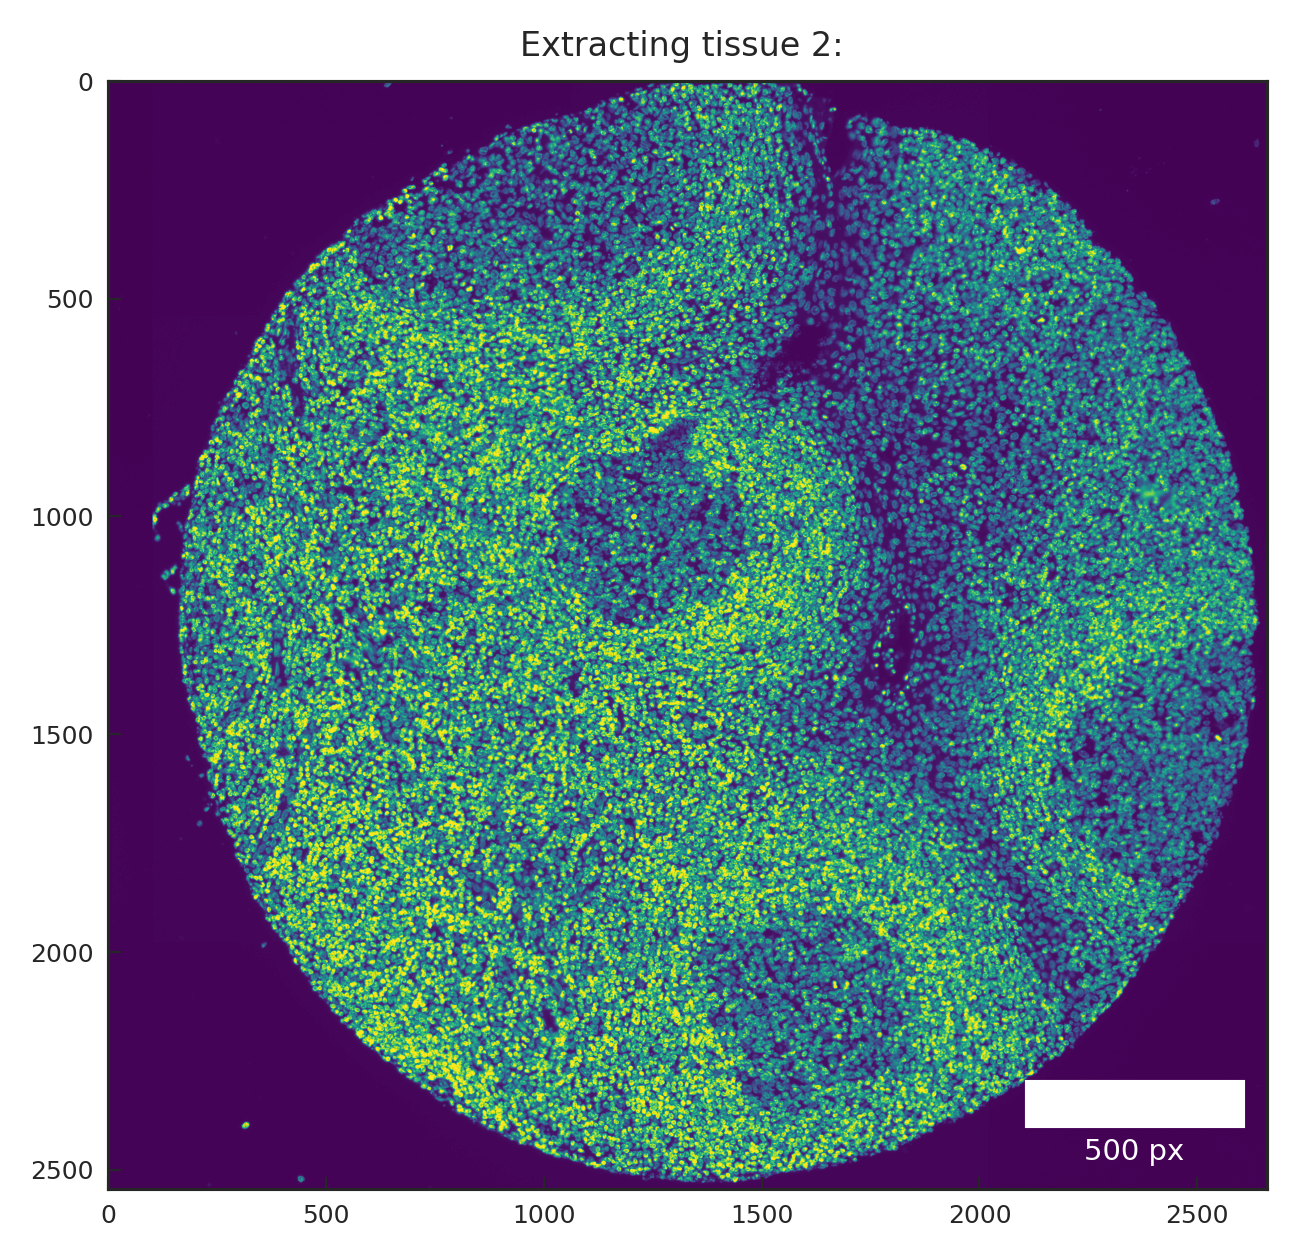

In [9]:
sp.tl.save_labelled_tissue(filepath=file_path, 
                           tissueframe=tissueframe, # the data frame with pixel assignment to each tissue piece or region
                           output_dir = output_dir, # where to store the image
                           downscale_factor = 64, # the downscale factor for the image
                           region = 'region1', 
                           padding = 50 # the padding to add to the image
                           )